In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, recall_score, precision_score, f1_score
from sklearn.tree import plot_tree
    
from pathlib import Path

In [3]:
data_path = Path("data/student-por.csv")

if not data_path.exists():
    data_path = Path("../data/student-por.csv")

# Stop with a clear error if the file cannot be found.
if not data_path.exists():
    raise FileNotFoundError("Could not find student-por.csv. Check the data folder.")

# Load the CSV file into a Pandas DataFrame.
df = pd.read_csv(data_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
# The first 5 rows of the dataset
df.head(5)

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [5]:
# The last 5 rows of the dataset
df.tail(5)

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
644,MS,F,19,R,GT3,T,2,3,services,other,...,5,4,2,1,2,5,4,10,11,10
645,MS,F,18,U,LE3,T,3,1,teacher,services,...,4,3,4,1,1,1,4,15,15,16
646,MS,F,18,U,GT3,T,1,1,other,other,...,1,1,1,1,1,5,6,11,12,9
647,MS,M,17,U,LE3,T,3,1,services,services,...,2,4,5,3,4,2,6,10,10,10
648,MS,M,18,R,LE3,T,3,2,services,other,...,4,4,1,3,4,5,4,10,11,11


In [6]:
# the no of rows and columns
df.shape

(649, 33)

In [7]:
# Listing all the column/feature names in the dataset
#df.columns

df.columns.tolist()

['school',
 'sex',
 'age',
 'address',
 'famsize',
 'Pstatus',
 'Medu',
 'Fedu',
 'Mjob',
 'Fjob',
 'reason',
 'guardian',
 'traveltime',
 'studytime',
 'failures',
 'schoolsup',
 'famsup',
 'paid',
 'activities',
 'nursery',
 'higher',
 'internet',
 'romantic',
 'famrel',
 'freetime',
 'goout',
 'Dalc',
 'Walc',
 'health',
 'absences',
 'G1',
 'G2',
 'G3']

In [8]:
# to know the info about our dataset (no of rows, col. names, data types, non-null values, memory usage)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      649 non-null    str  
 1   sex         649 non-null    str  
 2   age         649 non-null    int64
 3   address     649 non-null    str  
 4   famsize     649 non-null    str  
 5   Pstatus     649 non-null    str  
 6   Medu        649 non-null    int64
 7   Fedu        649 non-null    int64
 8   Mjob        649 non-null    str  
 9   Fjob        649 non-null    str  
 10  reason      649 non-null    str  
 11  guardian    649 non-null    str  
 12  traveltime  649 non-null    int64
 13  studytime   649 non-null    int64
 14  failures    649 non-null    int64
 15  schoolsup   649 non-null    str  
 16  famsup      649 non-null    str  
 17  paid        649 non-null    str  
 18  activities  649 non-null    str  
 19  nursery     649 non-null    str  
 20  higher      649 non-null    str  
 21  inte

In [9]:
# Checking for missing values in the dataset
df.isnull().sum()

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

In [10]:
# The total missing values in the entire dataset
df.isnull().sum().sum()

np.int64(0)

In [11]:
# Check for duplicate rows

df.duplicated().sum()

np.int64(0)

In [12]:
# Producing statistical summaries for numerical columns
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000
mean,16.744222,2.514638,2.306626,1.568567,1.930663,0.221880,3.930663,3.180277,3.184900,1.502311,2.280431,3.536210,3.659476,11.399076,11.570108,11.906009
std,1.218138,1.134552,1.099931,0.748660,0.829510,0.593235,0.955717,1.051093,1.175766,0.924834,1.284380,1.446259,4.640759,2.745265,2.913639,3.230656
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,16.000000,2.000000,1.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,2.000000,0.000000,10.000000,10.000000,10.000000
50%,17.000000,2.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,2.000000,11.000000,11.000000,12.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,6.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,32.000000,19.000000,19.000000,19.000000


In [13]:
# Understand categorical columns
df.describe(include="object")

C:\Users\user\AppData\Local\Temp\ipykernel_3456\38435206.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,school,sex,address,famsize,Pstatus,Mjob,Fjob,reason,guardian,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic
count,649,649,649,649,649,649,649,649,649,649,649,649,649,649,649,649,649
unique,2,2,2,2,2,5,5,4,3,2,2,2,2,2,2,2,2
top,GP,F,U,GT3,T,other,other,course,mother,no,yes,no,no,yes,yes,yes,no
freq,423,383,452,457,569,258,367,285,455,581,398,610,334,521,580,498,410


In [14]:
print(df.columns.tolist())

['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']


In [15]:
# Create a Pass/Fail column from the final grades (G3)
df["result"] = np.where(df["G3"] >= 10, "Pass", "Fail")

# Display the first five records.
df[["G3", "result"]].head()

,G3,result
0,11,Pass
1,11,Pass
2,12,Pass
3,14,Pass
4,13,Pass


In [16]:
# What proportion of students passed or failed?
df["result"].value_counts()

result
Pass    549
Fail    100
Name: count, dtype: int64

In [17]:
df["result"].value_counts(normalize=True) * 100

result
Pass    84.59168
Fail    15.40832
Name: proportion, dtype: float64

In [18]:
df.shape

(649, 34)

Visualize the distribution with Seaborn

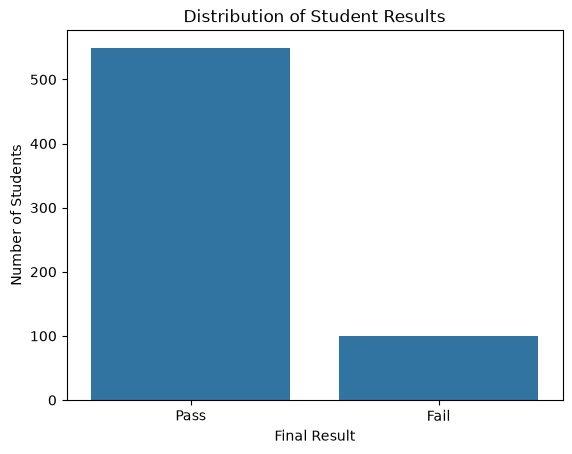

In [19]:
sns.countplot(data=df, x="result")

plt.title("Distribution of Student Results")
plt.xlabel("Final Result")
plt.ylabel("Number of Students")

plt.show()

In [20]:
# How are students distributed across study-time categories?
df["studytime"].value_counts().sort_index()

studytime
1    212
2    305
3     97
4     35
Name: count, dtype: int64

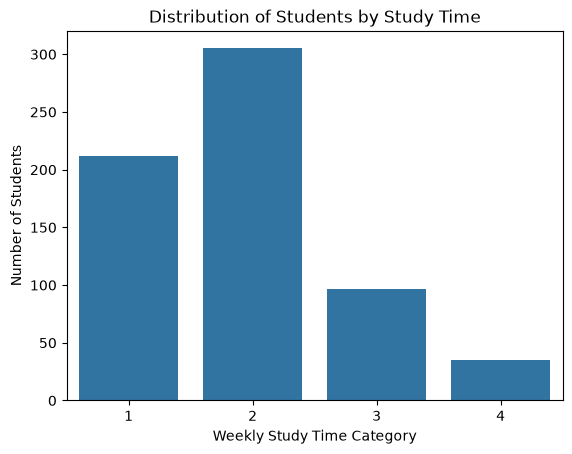

In [21]:
sns.countplot(data=df, x="studytime")

plt.title("Distribution of Students by Study Time")
plt.xlabel("Weekly Study Time Category")
plt.ylabel("Number of Students")

plt.show()

In [22]:
# How do previous grades relate to final grades?
df[["G1", "G2", "G3"]].describe()

,G1,G2,G3
count,649.000000,649.000000,649.000000
mean,11.399076,11.570108,11.906009
std,2.745265,2.913639,3.230656
min,0.000000,0.000000,0.000000
25%,10.000000,10.000000,10.000000
50%,11.000000,11.000000,12.000000
75%,13.000000,13.000000,14.000000
max,19.000000,19.000000,19.000000


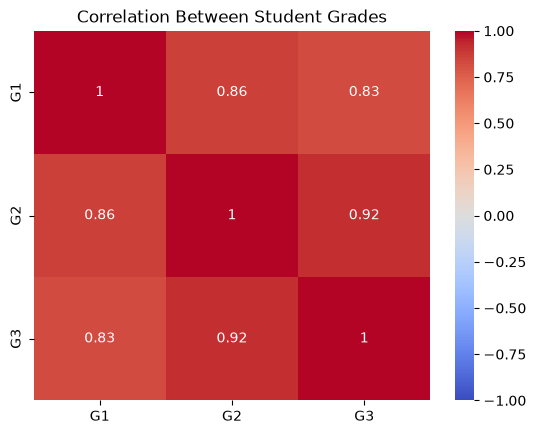

In [23]:
# correlation visualization
# Correlation measures the strength and direction of a relationship between two numerical variables.


grade_correlation = df[["G1", "G2", "G3"]].corr()

sns.heatmap(
    grade_correlation,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Student Grades")

plt.show()

In [24]:
# How does absenteeism vary among students?

df["absences"].describe()

count    649.000000
mean       3.659476
std        4.640759
min        0.000000
25%        0.000000
50%        2.000000
75%        6.000000
max       32.000000
Name: absences, dtype: float64

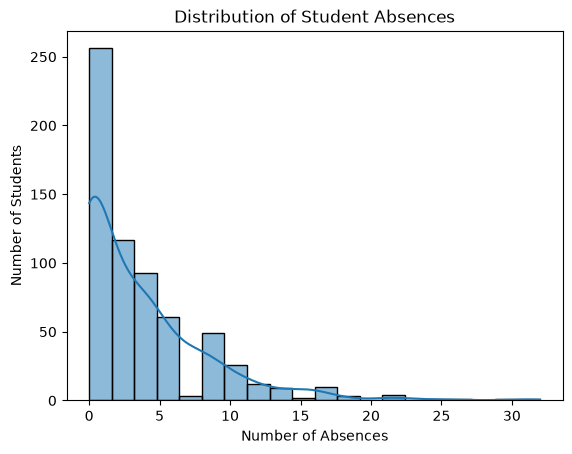

In [25]:
# Visualize the distribution of absenses
# A histogram helps us see where most observations are concentrated.

sns.histplot(data=df, x="absences", bins=20, kde=True)

plt.title("Distribution of Student Absences")
plt.xlabel("Number of Absences")
plt.ylabel("Number of Students")

plt.show()

In [26]:
df[["G1", "G2", "G3"]].corr()

,G1,G2,G3
G1,1.000000,0.864982,0.826387
G2,0.864982,1.000000,0.918548
G3,0.826387,0.918548,1.000000


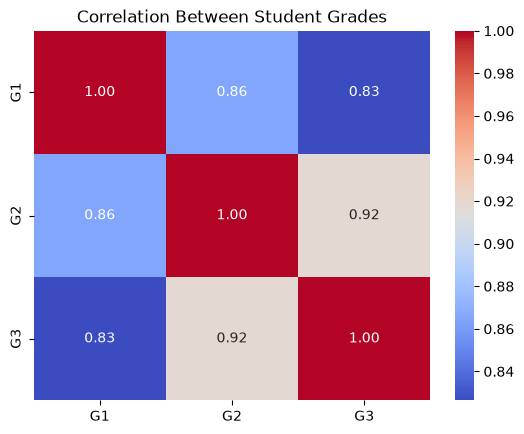

In [27]:
grade_corr = df[["G1", "G2", "G3"]].corr()

sns.heatmap(grade_corr, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Between Student Grades")
plt.show()

Supervised Machine Learning

Our features are :

- studytime – Weekly study-time category.
- absences – Number of student absences.
- failures – Number of previous class failures.
- G1 – First-period grade.
- G2 – Second-period grade.

The Target (y) is result

In [28]:
# Creating our feature variable

X = df[["studytime", "absences", "failures", "G1", "G2"]]

In [29]:
# Creating our target variable

y = df["result"]

In [30]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures preview:")
display(X.head())

print("\nTarget preview:")
display(y.head())

Features shape: (649, 5)
Target shape: (649,)

Features preview:


,studytime,absences,failures,G1,G2
0,2,4,0,0,11
1,2,2,0,9,11
2,2,6,0,12,13
3,3,0,0,14,14
4,2,0,0,11,13



Target preview:


0    Pass
1    Pass
2    Pass
3    Pass
4    Pass
Name: result, dtype: str

In [31]:
print(y.value_counts())

result
Pass    549
Fail    100
Name: count, dtype: int64


In [32]:
print(y.unique())

<StringArray>
['Pass', 'Fail']
Length: 2, dtype: str


Split the dataset into training and testing sets


In [33]:
# Splitting our data into training and testing sets
# from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [34]:
# Print our splitted data shapes

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (519, 5)
X_test: (130, 5)
y_train: (519,)
y_test: (130,)


Training our Model

We are using Decision Tree Classifier which is a machine learning algorithm that makes predictions by asking a series of questions.

In [35]:
# from sklearn.tree import DecisionTreeClassifier

# Creating the model

model = DecisionTreeClassifier(random_state=42)

# random_state=42 helps make the model's randomized behaviour reproducible.

In [36]:
# Training the model on the training data

model.fit(X_train, y_train)

# We train using .fit()

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [37]:
# Making Predictions

# Based on what you learned from the training data, would these students pass or fail?

y_pred = model.predict(X_test)

In [38]:
# View our prediction

print(y_pred[:10])

['Pass' 'Pass' 'Pass' 'Pass' 'Pass' 'Fail' 'Fail' 'Pass' 'Pass' 'Pass']


In [39]:
print(y_test[:10])

28     Pass
124    Pass
135    Pass
641    Pass
552    Pass
570    Fail
502    Fail
410    Pass
596    Pass
324    Pass
Name: result, dtype: str


In [40]:
# Comparing our prediction with the actual result

comparison = pd.DataFrame({
    "Actual Result": y_test.values,
    "Predicted Result": y_pred
})

display(comparison.head(10))

,Actual Result,Predicted Result
0,Pass,Pass
1,Pass,Pass
2,Pass,Pass
3,Pass,Pass
4,Pass,Pass
5,Fail,Fail
6,Fail,Fail
7,Pass,Pass
8,Pass,Pass
9,Pass,Pass


Evaluating our Model

1. Accuracy measures the percentage of predictions our model got correct.
2. A confusion matrix is a table that shows how many predictions were correct and how many were incorrect.
3. Precision answers this question: Of all the students our model predicted would fail, how many actually failed? (Precision helps us determine how trustworthy the model's positive predictions are.)
4. Recall: Of all students who actually belong to that class, how many did the model identify?

In [41]:
# Calculate accuracy

# from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy * 100:.2f}%")

Model Accuracy: 89.23%


In [42]:
# Calculate the confusion matrix to see how many predictions were correct and incorrect.(TP,TN,FP,FN)

# from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=["Fail", "Pass"])

print(cm)

[[ 13   7]
 [  7 103]]


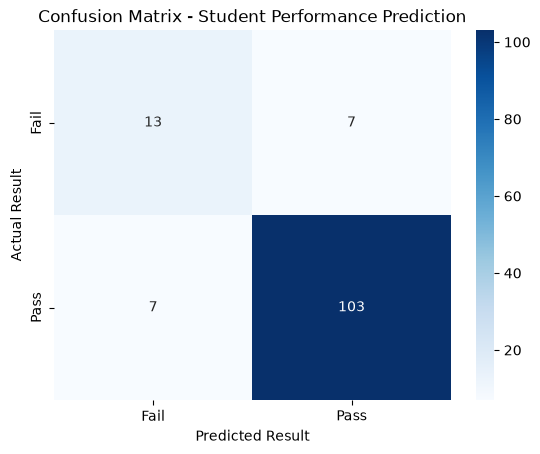

In [43]:
# Visualize the confusion matrix

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fail", "Pass"],
    yticklabels=["Fail", "Pass"]
)

plt.title("Confusion Matrix - Student Performance Prediction")
plt.xlabel("Predicted Result")
plt.ylabel("Actual Result")

plt.show()


In [44]:
# from sklearn.metrics import classification_report

# Calculate precision, recall and F1-score

# Precision:	How reliable the predictions are
# Recall:	How many actual cases the model identified
# F1-score:	Balance between precision and recall
# Support:	Number of actual students in each class

# Macro avg: Calculates the average performance across Pass and Fail, giving both classes equal importance.
# Weighted avg: Calculates the average while considering how many students belong to each class.

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

        Fail       0.65      0.65      0.65        20
        Pass       0.94      0.94      0.94       110

    accuracy                           0.89       130
   macro avg       0.79      0.79      0.79       130
weighted avg       0.89      0.89      0.89       130



In [45]:
# Understand feature importance

# Which student factors influenced the model's predictions the most? (feature Importance)
# feature importance shows how the decision tree uses features, not necessarily what causes students to pass or fail.

importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

display(importance)

,Feature,Importance
4,G2,0.616558
1,absences,0.148342
3,G1,0.128363
2,failures,0.071669
0,studytime,0.035068


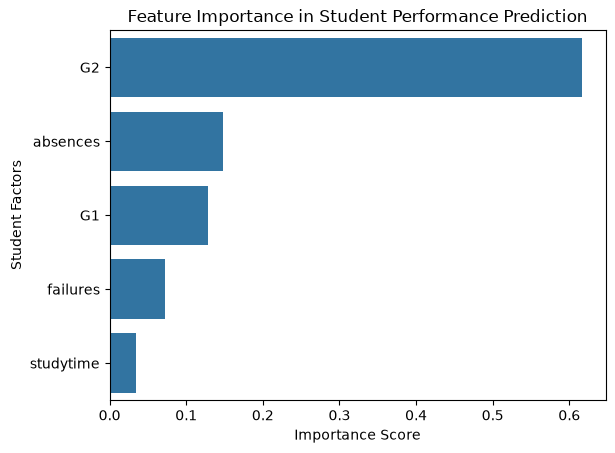

In [46]:
# Visualizing the feature Importance

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance in Student Performance Prediction")
plt.xlabel("Importance Score")
plt.ylabel("Student Factors")

plt.show()

In [47]:
# Our model relies heavily on G2 when predicting whether a student passes or fails.
# Feature importance does not prove causation.

## Model Improvement.

1. Overfitting — whether the tree has memorized the training data instead of learning patterns that generalize.


2. Tree depth — controlling how complex the decision tree becomes.


3. Model comparison — comparing our original tree with a controlled version.


4. Final evaluation — determining whether our changes improve performance, especially for the Fail class.

In [48]:
# Checking for overfitting

train_accuracy = model.score(X_train, y_train)
test_accuracy = model.score(X_test, y_test)

print(f"Training Accuracy: {train_accuracy * 100:.2f}%")
print(f"Testing Accuracy: {test_accuracy * 100:.2f}%")

Training Accuracy: 98.84%
Testing Accuracy: 89.23%


In [49]:
# What causes overfitting?
# A Decision Tree can keep creating branches and asking more questions until it becomes very complex.

# For example, imagine a tree that creates very specific rules for individual students.

# It might memorize the training data extremely well, but struggle when it encounters a new student.

# That's why we need to control the tree's complexity.

# How do we reduce overfitting?
# One way is to control the tree's maximum depth using max_depth.

# Think of maximum depth as the number of decision levels the tree is allowed to create.
# A very deep tree can become overly complex.
# A shallow tree is simpler but might miss important patterns.
# We want a balance.

## Creating a second Decision Tree Classifier.

In [50]:
# Creating a second Decision Tree model with a max depth of 3

model_2 = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

In [51]:
# Training the new model

model_2.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

In [52]:
# Calculate the training and testing accuracy for the new model

train_accuracy_2 = model_2.score(X_train, y_train)
test_accuracy_2 = model_2.score(X_test, y_test)

print(f"Training Accuracy: {train_accuracy_2 * 100:.2f}%")
print(f"Testing Accuracy: {test_accuracy_2 * 100:.2f}%")

Training Accuracy: 94.80%
Testing Accuracy: 90.77%


In [53]:
# Generating the predictions for the new model

y_pred_2 = model_2.predict(X_test)

In [54]:
# The prediction report

print(classification_report(y_test, y_pred_2))

              precision    recall  f1-score   support

        Fail       0.68      0.75      0.71        20
        Pass       0.95      0.94      0.94       110

    accuracy                           0.91       130
   macro avg       0.82      0.84      0.83       130
weighted avg       0.91      0.91      0.91       130



In [55]:
# Generating the confusion matrix

cm_2 = confusion_matrix(
    y_test,
    y_pred_2,
    labels=["Fail", "Pass"]
)

print(cm_2)

[[ 15   5]
 [  7 103]]


## Reducing the tree depth:
- Improved testing accuracy.
- Reduced the training/testing accuracy gap.
- Improved Fail precision, recall and F1-score.
- Reduced the number of missed Fail students from 7 to 5.
This is evidence that controlling model complexity helped generalization on this test split.

In [56]:
# Comparing different tree depths

depths = [2, 3, 4, 5, 6, 8, 10]

results = []

for depth in depths:
    tree = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

In [57]:
# training the model "Tree"

tree.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples i

In [58]:
# Checking tha accuracy of the data

train_acc = tree.score(X_train, y_train)
test_acc = tree.score(X_test, y_test)

In [59]:
# Prediction

predictions = tree.predict(X_test)

In [60]:
report = classification_report(
        y_test,
        predictions,
        output_dict=True,
        zero_division=0
    )

In [61]:
results.append({
        "Max Depth": depth,
        "Training Accuracy": train_acc,
        "Testing Accuracy": test_acc,
        "Fail Precision": report["Fail"]["precision"],
        "Fail Recall": report["Fail"]["recall"],
        "Fail F1-score": report["Fail"]["f1-score"]
    })

In [62]:
depth_results = pd.DataFrame(results)

display(depth_results.round(3))

,Max Depth,Training Accuracy,Testing Accuracy,Fail Precision,Fail Recall,Fail F1-score
0,10,0.987,0.892,0.65,0.65,0.65


In [63]:
# Creating the depth 4 candidate model

model_3 = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

model_3.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

In [64]:
# Evaluating the prediction

y_pred_3 = model_3.predict(X_test)

print(classification_report(y_test, y_pred_3))

              precision    recall  f1-score   support

        Fail       0.75      0.75      0.75        20
        Pass       0.95      0.95      0.95       110

    accuracy                           0.92       130
   macro avg       0.85      0.85      0.85       130
weighted avg       0.92      0.92      0.92       130



In [65]:
# Checking the confusion matrix

cm_3 = confusion_matrix(
    y_test,
    y_pred_3,
    labels=["Fail", "Pass"]
)

print(cm_3)

[[ 15   5]
 [  5 105]]


## Validate the model using cross-validation

# Cross-validation is a resampling technique used in machine learning to evaluate how well a model generalizes to unseen data and to prevent overfitting.

Instead of relying on a single train-test split—which can produce misleading results depending on which data points land in each set—cross-validation repeatedly splits the data into multiple subsets, trains the model on some, and validates it on the others.

Before we declare depth 4 our final model, we need to check whether it performs consistently across different portions of the training data.

Why? Your current 92.31% accuracy comes from one train/test split. A different split could produce a different result.

Step 1: Understand cross-validation
We'll use 5-fold stratified cross-validation.

The process:
1. Divide the training data into five parts.
2. Train on four parts and validate on the remaining part.
3. Repeat until each part has served as the validation set.
4. Calculate the average performance across all five rounds.
Stratified means each fold maintains approximately the same Pass/Fail proportions as the original training data.

In [66]:
# from sklearn.model_selection import StratifiedKFold, cross_validate
# from sklearn.metrics import make_scorer, recall_score, precision_score, f1_score

# We use StratifiedKFold because we want to maintain approximately the same proportion of Pass and Fail students in each fold.

# That is particularly useful because our dataset has more Pass students than Fail students.

# Configure cross validation

# Divide the training data into five stratified folds
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# We want to pay particular attention to identifying students who may fail.
fail_precision = make_scorer(
    precision_score,
    pos_label="Fail",
    zero_division=0
)

fail_recall = make_scorer(
    recall_score,
    pos_label="Fail",
    zero_division=0
)

fail_f1 = make_scorer(
    f1_score,
    pos_label="Fail",
    zero_division=0
)

In [67]:
# Evaluate depth 4 Model

scoring = {
    "accuracy": "accuracy",
    "fail_precision": fail_precision,
    "fail_recall": fail_recall,
    "fail_f1": fail_f1
}

cv_results = cross_validate(
    DecisionTreeClassifier(max_depth=4, random_state=42),
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

# Display the results from all five folds
cv_scores = pd.DataFrame({
    "Accuracy": cv_results["test_accuracy"],
    "Fail Precision": cv_results["test_fail_precision"],
    "Fail Recall": cv_results["test_fail_recall"],
    "Fail F1": cv_results["test_fail_f1"]
})

display(cv_scores.round(3))

,Accuracy,Fail Precision,Fail Recall,Fail F1
0,0.933,0.909,0.625,0.741
1,0.933,0.737,0.875,0.800
2,0.904,0.714,0.625,0.667
3,0.913,0.733,0.688,0.710
4,0.883,0.591,0.812,0.684


In [68]:
# Calculate the average scores

print("Average Cross-Validation Results:")
display(cv_scores.mean().round(3))

Average Cross-Validation Results:


Accuracy          0.913
Fail Precision    0.737
Fail Recall       0.725
Fail F1           0.720
dtype: float64

In [69]:
# Store the selected model's cross-validation averages
final_cv_summary = cv_scores.mean()

print("DECISION TREE MODEL — CROSS-VALIDATION SUMMARY")
print("----------------------------------------------")

for metric, score in final_cv_summary.items():
    print(f"{metric}: {score * 100:.2f}%")

DECISION TREE MODEL — CROSS-VALIDATION SUMMARY
----------------------------------------------
Accuracy: 91.32%
Fail Precision: 73.69%
Fail Recall: 72.50%
Fail F1: 72.03%


## Visualizing the Decision Tree

A Decision Tree makes predictions by asking a sequence of questions about student information.

For example:
- Is the student's G2 grade above a certain value?
- Has the student had previous class failures?
- How many absences does the student have?
The answers determine the path through the tree until it reaches a Pass or Fail prediction

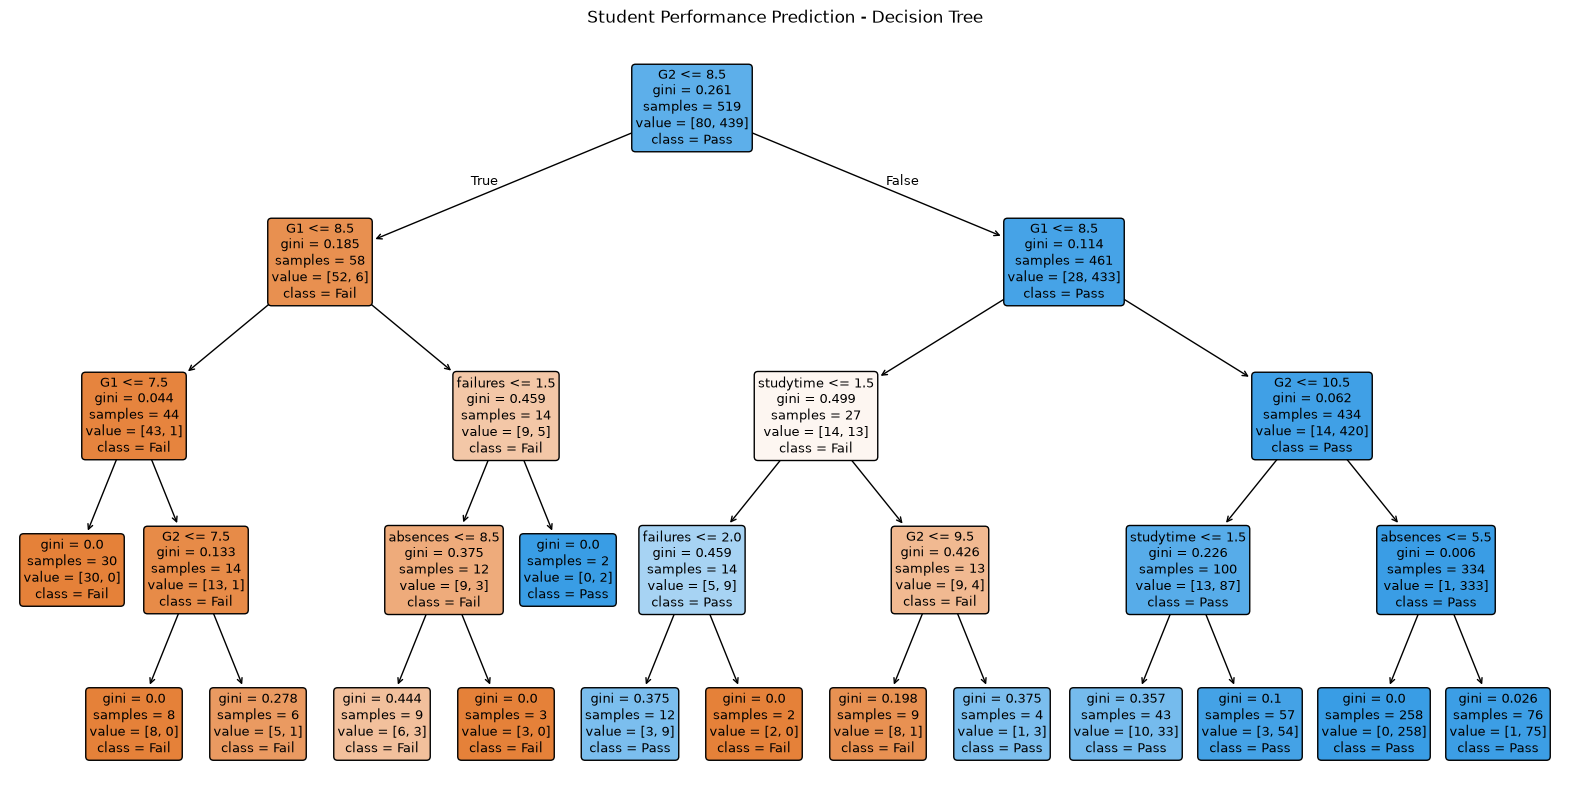

In [70]:
# from sklearn.tree import plot_tree

# Draw the depth 4 tree

plt.figure(figsize=(20, 10))

plot_tree(
    model_3,
    feature_names=X.columns,
    class_names=model_3.classes_,
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Student Performance Prediction - Decision Tree")
plt.show()

The meaning of our root node

G2 <= 8.5:	The first question the model asks


Gini measures how mixed the classes are in a node.
- Gini = 0 means all students in that node belong to one class.
- A higher Gini means the node contains a more mixed combination of Pass and Fail students.

gini = 0.261:	How mixed the Pass and Fail students are

samples = 519:	All 519 training students are represented here

value = [80, 439]:	80 Fail students and 439 Pass students

class = Pass:	Pass is the majority class

## Understand what you're looking at

Pay attention to these:
- Root node: The first question the model asks.
- Branches: The possible answers to each question.
- Leaf nodes: The final predictions.
- Gini: A measure of how mixed the Pass and Fail classes are in a node. Lower is better.
- Samples: Number of training students represented in that node.
- Value: Number of Fail and Pass students in that node, in the model's class order.
- Class: The predicted class at that node.

The tree is limited to four levels of depth, making it easier to interpret than the unrestricted model.

In [71]:
# Testing our model

# Create sample student records using the same features used for training
sample_students = pd.DataFrame({
    "studytime": [2, 3, 1],
    "absences": [2, 5, 15],
    "failures": [0, 0, 2],
    "G1": [14, 10, 5],
    "G2": [15, 11, 6]
})

# Make predictions using our depth-4 Decision Tree
sample_predictions = model_3.predict(sample_students)

# Display the students and their predicted results
sample_students["Predicted Result"] = sample_predictions

display(sample_students)


,studytime,absences,failures,G1,G2,Predicted Result
0,2,2,0,14,15,Pass
1,3,5,0,10,11,Pass
2,1,15,2,5,6,Fail


In [72]:
# Install Joblib to ssave our trained model

%pip install joblib

Note: you may need to restart the kernel to use updated packages.


In [73]:
import joblib
from pathlib import Path

# Create a folder for saved models
Path("../models").mkdir(exist_ok=True)

# Save our trained Decision Tree
joblib.dump(model_3, "../models/student_performance_model.joblib")

print("Model saved successfully!")

Model saved successfully!


In [74]:
# Test to see if it can be loaded

# Load the saved model
loaded_model = joblib.load("../models/student_performance_model.joblib")

# Make a prediction using the loaded model
loaded_prediction = loaded_model.predict(sample_students.drop(columns=["Predicted Result"]))

print("Loaded model predictions:", loaded_prediction)

Loaded model predictions: ['Pass' 'Pass' 'Fail']
